### PREPROCESSING PIPELINE

In [12]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.preprocessing import LabelEncoder

data_dir = Path("../data/raw/CICIDS2017")

files = list(data_dir.glob("*.parquet"))

df = pd.concat(
    [pd.read_parquet(file) for file in files],
    ignore_index=True
)

df.columns = df.columns.str.strip()

print(df.shape)

(2313810, 78)


In [13]:
## data cleaning and handling missing values
import numpy as np
import pandas as pd

# Replace infinite values with NaN
df_clean = df.replace([np.inf, -np.inf], np.nan)

# Drop non-numeric columns if present
df_clean = df_clean.select_dtypes(include=[np.number])

# Drop columns where standard deviation is 0 or NaN
std = df_clean.std()
valid_cols = std[std > 0].index
df_clean = df_clean[valid_cols]

# Impute or drop remaining missing values
print("Shape before handling missing values:", df_clean.shape)
print("Rows containing missing values:", df_clean.isna().any(axis=1).sum())
print("Missing values per column:")
print(df_clean.isna().sum().sort_values(ascending=False).head(20))

Shape before handling missing values: (2313810, 69)
Rows containing missing values: 0
Missing values per column:
Protocol                    0
Flow Duration               0
Total Fwd Packets           0
Total Backward Packets      0
Fwd Packets Length Total    0
Bwd Packets Length Total    0
Fwd Packet Length Max       0
Fwd Packet Length Min       0
Fwd Packet Length Mean      0
Fwd Packet Length Std       0
Bwd Packet Length Max       0
Bwd Packet Length Min       0
Bwd Packet Length Mean      0
Bwd Packet Length Std       0
Flow Bytes/s                0
Flow Packets/s              0
Flow IAT Mean               0
Flow IAT Std                0
Flow IAT Max                0
Flow IAT Min                0
dtype: int64


In [14]:
## LABEL ENCODING
from sklearn.preprocessing import LabelEncoder

# Create the encoder
label_encoder = LabelEncoder()

# Encode the target column
df["Label"] = label_encoder.fit_transform(df["Label"].astype(str).str.strip())

print(df["Label"].unique())
print(df[["Label"]].head())

[ 0  1  7 11  2  6  5  4  3  8  9 10 12 14 13]
   Label
0      0
1      0
2      0
3      0
4      0


In [15]:
print(dict(zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
)))

{'Benign': np.int64(0), 'Bot': np.int64(1), 'DDoS': np.int64(2), 'DoS GoldenEye': np.int64(3), 'DoS Hulk': np.int64(4), 'DoS Slowhttptest': np.int64(5), 'DoS slowloris': np.int64(6), 'FTP-Patator': np.int64(7), 'Heartbleed': np.int64(8), 'Infiltration': np.int64(9), 'PortScan': np.int64(10), 'SSH-Patator': np.int64(11), 'Web Attack � Brute Force': np.int64(12), 'Web Attack � Sql Injection': np.int64(13), 'Web Attack � XSS': np.int64(14)}


In [16]:
## splitting
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["Label"], errors="ignore")
y = df.loc[X.index, "Label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

In [17]:
# Calculate absolute feature-to-feature correlations
corr_matrix = X_train.corr().abs()

# Consider only the upper triangle to avoid duplicate pairs
upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Remove the later feature from highly correlated pairs
threshold = 0.90

to_drop = [
    column
    for column in upper_tri.columns
    if (upper_tri[column] > threshold).any()
]

print("Highly correlated features removed:", len(to_drop))
print(to_drop)

# Apply the same feature removal to every split
X_train = X_train.drop(columns=to_drop)
X_val = X_val.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)

print("Training shape after correlation removal:", X_train.shape)

Highly correlated features removed: 30
['Total Backward Packets', 'Bwd Packets Length Total', 'Fwd Packet Length Std', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow IAT Max', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Bwd IAT Min', 'Fwd Packets/s', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'SYN Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'Avg Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'Active Min', 'Idle Mean', 'Idle Max', 'Idle Min']
Training shape after correlation removal: (1619667, 39)


In [ ]:
import pandas as pd
from sklearn.feature_selection import mutual_info_classif

# 1. Compute Mutual Information scores on training data (classification)
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)

# 2. Create a Pandas Series to easily view and filter features by MI score
mi_series = pd.Series(mi_scores, index=X_train.columns).sort_values(ascending=False)

print("Top 20 Features by Mutual Information Score:")
print(mi_series.head(20))

# Keep top K features (e.g., top 20) ---
k_features = 20
selected_features = mi_series.head(k_features).index.tolist()

# 3. Filter train, val, and test sets using the selected features
X_train = X_train[selected_features]
X_val = X_val[selected_features]
X_test = X_test[selected_features]

print(f"\nFinal X_train shape after MI selection: {X_train.shape}")

Top 30 Features by Mutual Information Score:
Bwd Packet Length Max       0.402438
Fwd Packets Length Total    0.399123
Fwd Packet Length Max       0.386641
Init Fwd Win Bytes          0.385065
Init Bwd Win Bytes          0.383564
Flow Duration               0.346134
Fwd Packet Length Mean      0.342192
Bwd Header Length           0.328694
Fwd Header Length           0.322800
Flow IAT Std                0.319751
Bwd Packets/s               0.314045
Flow IAT Mean               0.307508
Flow Packets/s              0.306140
Flow Bytes/s                0.297054
Bwd IAT Max                 0.291250
Bwd IAT Total               0.270611
Bwd IAT Mean                0.252073
Active Mean                 0.234189
Bwd IAT Std                 0.232349
Active Max                  0.231930
dtype: float64

Final X_train shape after MI selection: (1619667, 20)


In [24]:
## STANDARD SCALER
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

#fit() learns the mean and standard deviation.
#transform() uses those learned values to scale the data.
#Using fit_transform() on the entire dataset would leak information from the validation and test sets into preprocessing.

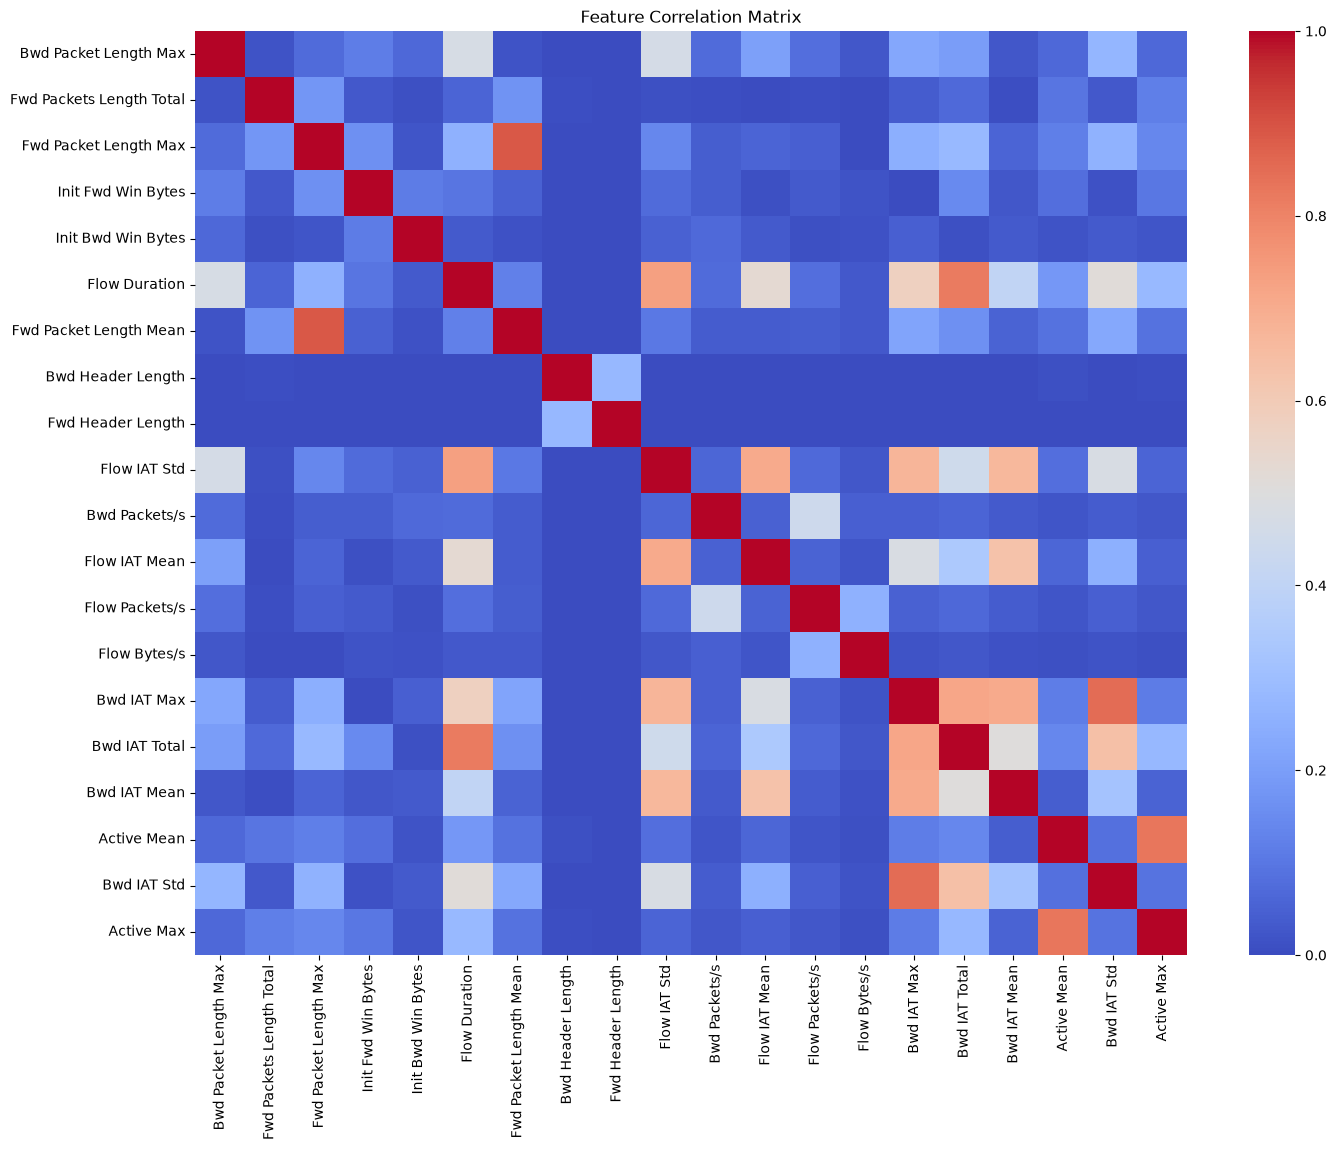

In [25]:
## CORRELATION ANALYSIS
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate feature-to-feature correlations
correlation_matrix = X_train.corr().abs()

# Plot the correlation matrix
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=0,
    vmax=1
)

plt.title("Feature Correlation Matrix")
plt.show()

In [26]:
## save for later
import joblib
import json
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save selected feature names
with open(models_dir / "selected_features.json", "w") as f:
    json.dump(selected_features, f, indent=4)

# Save fitted scaler
joblib.dump(scaler, models_dir / "scaler.pkl")

# Save target label mapping
joblib.dump(label_encoder, models_dir / "label_encoder.pkl")

print("Preprocessing artifacts saved successfully.")

Preprocessing artifacts saved successfully.


In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

# Quick 10-second proxy check
proxy_model = DecisionTreeClassifier(max_depth=10, random_state=42)

for k in [10, 15, 20, 25, 30]:
    top_k = mi_series.head(k).index.tolist()
    
    # Train proxy model on a small sample or full train set
    proxy_model.fit(X_train[top_k], y_train)
    preds = proxy_model.predict(X_val[top_k])
    
    score = f1_score(y_val, preds, average='macro')
    print(f"Top {k} features -> Validation Macro F1: {score:.4f}")

Top 10 features -> Validation Macro F1: 0.6250
Top 15 features -> Validation Macro F1: 0.6589
Top 20 features -> Validation Macro F1: 0.6599
Top 25 features -> Validation Macro F1: 0.6599
Top 30 features -> Validation Macro F1: 0.6599
